--- PARQUET FILE ---
Rows: 3,702,647
Row groups: 4
Columns: ['station', 'time', 'wsi', 'stationname', 'lat', 'lon', 'T', 'U', 'DD', 'FH']
Processed 2,000,000 rows...

Finished processing 3,702,647 rows.

--- MISSING VALUES: FULL DATASET ---
             missing_count  missing_percent
station                  0             0.00
time                     0             0.00
wsi                      0             0.00
stationname              0             0.00
lat                      0             0.00
lon                      0             0.00
T                   857402            23.16
U                   877063            23.69
DD                  150418             4.06
FH                  129716             3.50

--- STATIONS AND TIME: FULL DATASET ---
Unique station IDs: 70
Earliest parsed time: 2020-01-01 01:00:00+00:00
Latest parsed time:   2026-10-29 00:00:00+00:00
Non-missing times that could not be parsed: 0

Records per station:
  0-20000-0-06201: 59,832
  0-20000-0-06203: 59

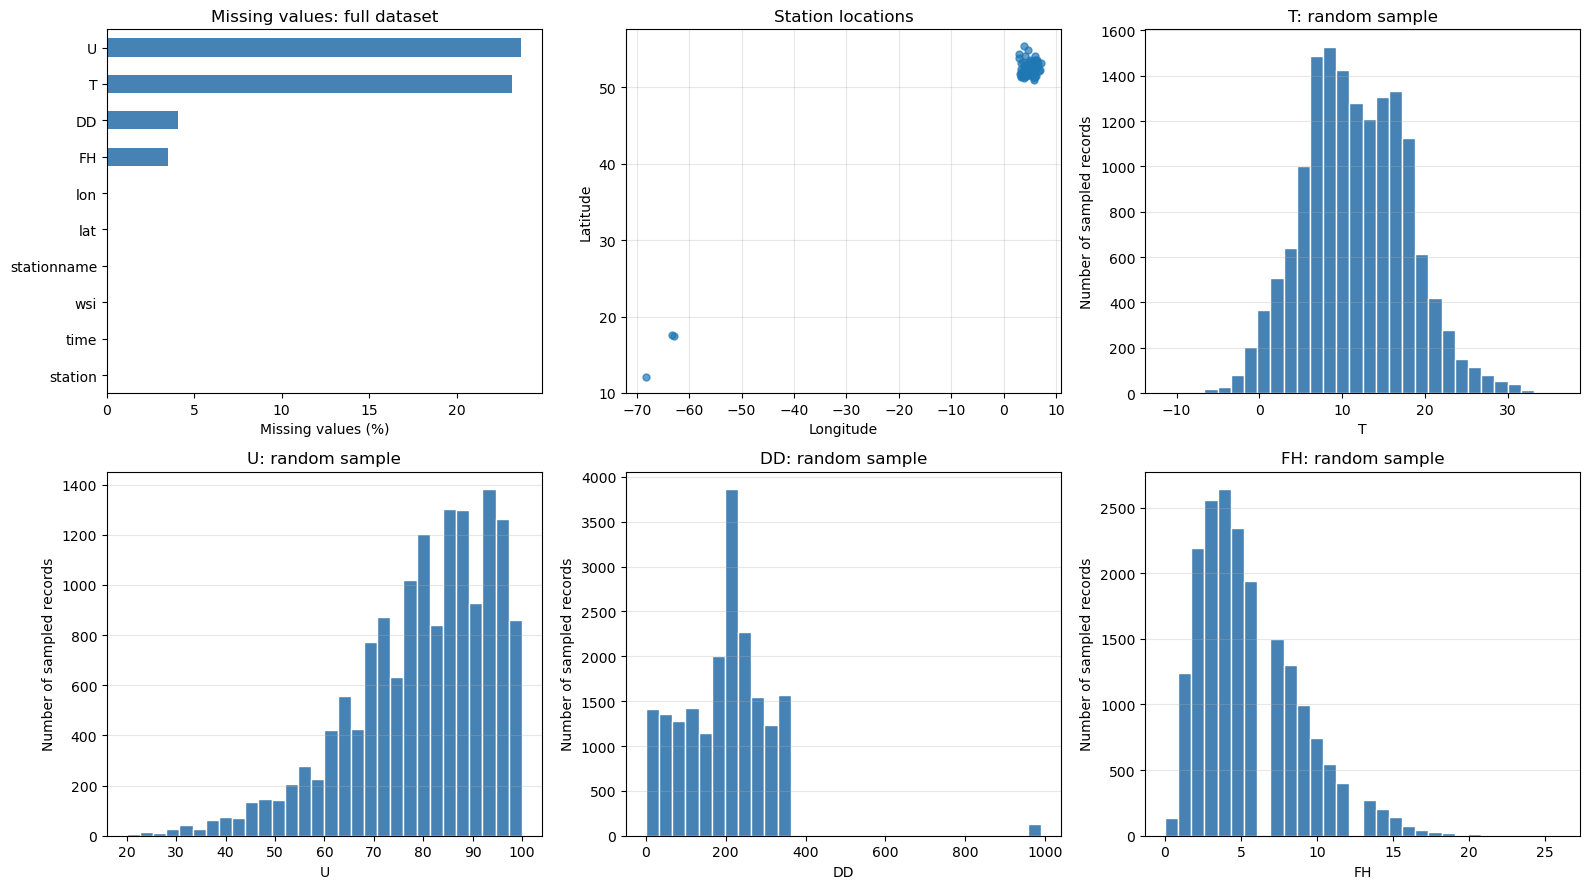

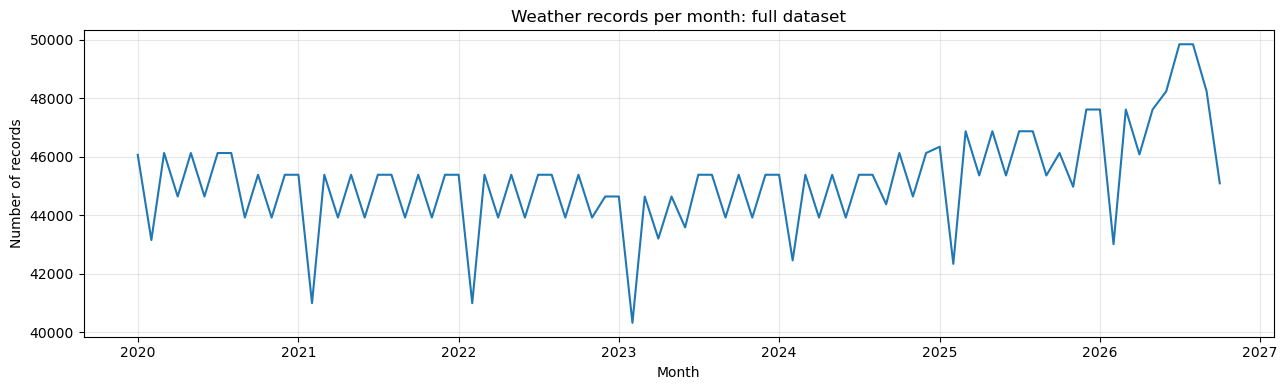

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from collections import Counter

# --------------------------------------------------
# Settings
# --------------------------------------------------
FILE_PATH = r"../data/knmi_weather_data.parquet"  # relative to notebooks/

BATCH_SIZE = 100_000
SAMPLE_SIZE = 20_000

COLUMNS = [
    "station", "time", "wsi", "stationname",
    "lat", "lon", "T", "U", "DD", "FH"
]

WEATHER_COLUMNS = ["T", "U", "DD", "FH"]

rng = np.random.default_rng(42)

# --------------------------------------------------
# Open Parquet file without loading it all into memory
# --------------------------------------------------
parquet_file = pq.ParquetFile(FILE_PATH)

print("--- PARQUET FILE ---")
print(f"Rows: {parquet_file.metadata.num_rows:,}")
print(f"Row groups: {parquet_file.num_row_groups:,}")
print(f"Columns: {parquet_file.schema_arrow.names}")

missing_columns = [
    col for col in COLUMNS
    if col not in parquet_file.schema_arrow.names
]

if missing_columns:
    raise ValueError(f"Expected columns not found: {missing_columns}")

# Aggregates across all batches
missing_counts = pd.Series(0, index=COLUMNS, dtype="int64")
station_counts = Counter()
monthly_counts = Counter()
station_locations = {}

total_rows = 0
time_parse_failures = 0
earliest_time = None
latest_time = None
sample = None

# --------------------------------------------------
# Helper: parse common time formats
# --------------------------------------------------
def parse_time(series):
    # Convert to text so compact numeric dates are not
    # interpreted as nanoseconds since 1970.
    text = series.astype("string").str.strip()
    text = text.str.replace(r"\.0$", "", regex=True)

    result = pd.Series(
        pd.NaT,
        index=series.index,
        dtype="datetime64[ns, UTC]"
    )

    compact_mask = pd.Series(False, index=series.index)

    formats = {
        8: "%Y%m%d",
        10: "%Y%m%d%H",
        12: "%Y%m%d%H%M",
        14: "%Y%m%d%H%M%S"
    }

    for length, date_format in formats.items():
        mask = text.str.fullmatch(rf"\d{{{length}}}", na=False)
        compact_mask |= mask

        result.loc[mask] = pd.to_datetime(
            text.loc[mask],
            format=date_format,
            errors="coerce",
            utc=True
        )

    other = ~compact_mask & text.notna()

    result.loc[other] = pd.to_datetime(
        text.loc[other],
        errors="coerce",
        utc=True
    )

    return result

# --------------------------------------------------
# Process the file batch by batch
# --------------------------------------------------
for batch_number, arrow_batch in enumerate(
    parquet_file.iter_batches(
        batch_size=BATCH_SIZE,
        columns=COLUMNS
    ),
    start=1
):
    batch = arrow_batch.to_pandas()
    total_rows += len(batch)

    # Missing values in the original columns
    missing_counts += batch[COLUMNS].isna().sum()

    # Station counts
    station_counts.update(
        batch["station"]
        .dropna()
        .astype(str)
        .value_counts()
        .to_dict()
    )

    # Time coverage and records per month
    parsed_time = parse_time(batch["time"])

    time_parse_failures += (
        batch["time"].notna() & parsed_time.isna()
    ).sum()

    valid_time = parsed_time.dropna()

    if not valid_time.empty:
        batch_min = valid_time.min()
        batch_max = valid_time.max()

        earliest_time = (
            batch_min if earliest_time is None
            else min(earliest_time, batch_min)
        )
        latest_time = (
            batch_max if latest_time is None
            else max(latest_time, batch_max)
        )

        monthly_counts.update(
            valid_time.dt.strftime("%Y-%m").value_counts().to_dict()
        )

    # Keep the first valid coordinate pair encountered per station.
    for col in ["lat", "lon"]:
        batch[col] = pd.to_numeric(batch[col], errors="coerce")

    locations = (
        batch[["station", "lat", "lon"]]
        .dropna()
        .drop_duplicates(subset="station")
    )

    for row in locations.itertuples(index=False):
        station_locations.setdefault(
            str(row.station), (row.lat, row.lon)
        )

    # Uniform random sample across all rows, kept bounded in size.
    weather = batch[WEATHER_COLUMNS].apply(
        pd.to_numeric, errors="coerce"
    )
    weather = weather.replace([np.inf, -np.inf], np.nan)
    weather["_random_key"] = rng.random(len(weather))

    if sample is None:
        sample = weather
    else:
        sample = pd.concat([sample, weather], ignore_index=True)

    sample = sample.nsmallest(SAMPLE_SIZE, "_random_key")

    if batch_number % 20 == 0:
        print(f"Processed {total_rows:,} rows...")

print(f"\nFinished processing {total_rows:,} rows.")

# --------------------------------------------------
# Print EDA summaries
# --------------------------------------------------
print("\n--- MISSING VALUES: FULL DATASET ---")
missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": (
        100 * missing_counts / total_rows if total_rows else 0
    )
})
print(missing_summary.to_string(float_format=lambda x: f"{x:.2f}"))

print("\n--- STATIONS AND TIME: FULL DATASET ---")
print(f"Unique station IDs: {len(station_counts):,}")
print(f"Earliest parsed time: {earliest_time}")
print(f"Latest parsed time:   {latest_time}")
print(f"Non-missing times that could not be parsed: {time_parse_failures:,}")

print("\nRecords per station:")
for station, count in station_counts.most_common():
    print(f"  {station}: {count:,}")

if sample is not None and not sample.empty:
    print(f"\n--- WEATHER SUMMARY: RANDOM SAMPLE OF {len(sample):,} ROWS ---")
    print(
        sample[WEATHER_COLUMNS]
        .describe()
        .to_string(float_format=lambda x: f"{x:.2f}")
    )

    # --------------------------------------------------
    # Plots
    # --------------------------------------------------
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    # Full-data missingness
    missing_summary["missing_percent"].sort_values().plot.barh(
        ax=axes[0, 0], color="steelblue"
    )
    axes[0, 0].set_title("Missing values: full dataset")
    axes[0, 0].set_xlabel("Missing values (%)")

    # First recorded coordinates for each station
    location_df = pd.DataFrame.from_dict(
        station_locations,
        orient="index",
        columns=["lat", "lon"]
    )

    axes[0, 1].scatter(
        location_df["lon"], location_df["lat"], s=25, alpha=0.7
    )
    axes[0, 1].set_title("Station locations")
    axes[0, 1].set_xlabel("Longitude")
    axes[0, 1].set_ylabel("Latitude")
    axes[0, 1].grid(alpha=0.3)

    # Histograms based on the random sample
    weather_axes = [axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]]

    for col, ax in zip(WEATHER_COLUMNS, weather_axes):
        values = sample[col].dropna()

        if values.empty:
            ax.text(0.5, 0.5, "No valid values", ha="center")
        else:
            ax.hist(values, bins=30, color="steelblue", edgecolor="white")

        ax.set_title(f"{col}: random sample")
        ax.set_xlabel(col)
        ax.set_ylabel("Number of sampled records")
        ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Full-data record counts by month
    if monthly_counts:
        monthly = pd.Series(monthly_counts).sort_index()
        monthly.index = pd.to_datetime(monthly.index)

        plt.figure(figsize=(13, 4))
        plt.plot(monthly.index, monthly.values)
        plt.title("Weather records per month: full dataset")
        plt.xlabel("Month")
        plt.ylabel("Number of records")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()